In [1]:
#matplotlib inline
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="darkgrid")

# Basis-Pfad setzen
base_path = Path("KIS2_Data")

# Dateilisten
defect_files = [
    "Simulation_Data10004.hdf5", "Simulation_Data10005.hdf5", 
    "Simulation_Data10009.hdf5", "Simulation_Data10013.hdf5", 
    "Simulation_Data10018.hdf5"
]
no_defect_files = [
    "Simulation_Data1000.hdf5", "Simulation_Data1001.hdf5", 
    "Simulation_Data10006.hdf5", "Simulation_Data10008.hdf5", 
    "Simulation_Data10010.hdf5"
]

In [2]:
def plot_hdf5_to_ax(file_path, ax, title):
    with h5py.File(file_path, 'r') as f:
        data_cube = np.array(f['Data']['Tdata']) 
        ground_truth = np.array(f['GroundTruth']['DefectMask'])
        lut = np.array(f['MetaData']['LookUpTable'])
        time_vector = np.array(f['MetaData']['DomainValues'])

    # Intakten Pixel (GroundTruth == 0) suchen & plotten
    healthy_coords = np.argwhere(ground_truth == 0)
    hea_y, hea_x = healthy_coords[0]
    curve_healthy = lut[data_cube[hea_y, hea_x, :]]
    ax.plot(time_vector, curve_healthy, label=f"Intakt ({hea_y},{hea_x})", color='blue', linewidth=1.5)

    # Defekten Pixel (GroundTruth > 0) suchen & plotten (falls vorhanden)
    defect_coords = np.argwhere(ground_truth > 0)
    if len(defect_coords) > 0:
        def_y, def_x = defect_coords[0]
        curve_defect = lut[data_cube[def_y, def_x, :]]
        ax.plot(time_vector, curve_defect, label=f"Defekt ({def_y},{def_x})", color='red', linewidth=1.5)
    
    ax.set_title(title, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)

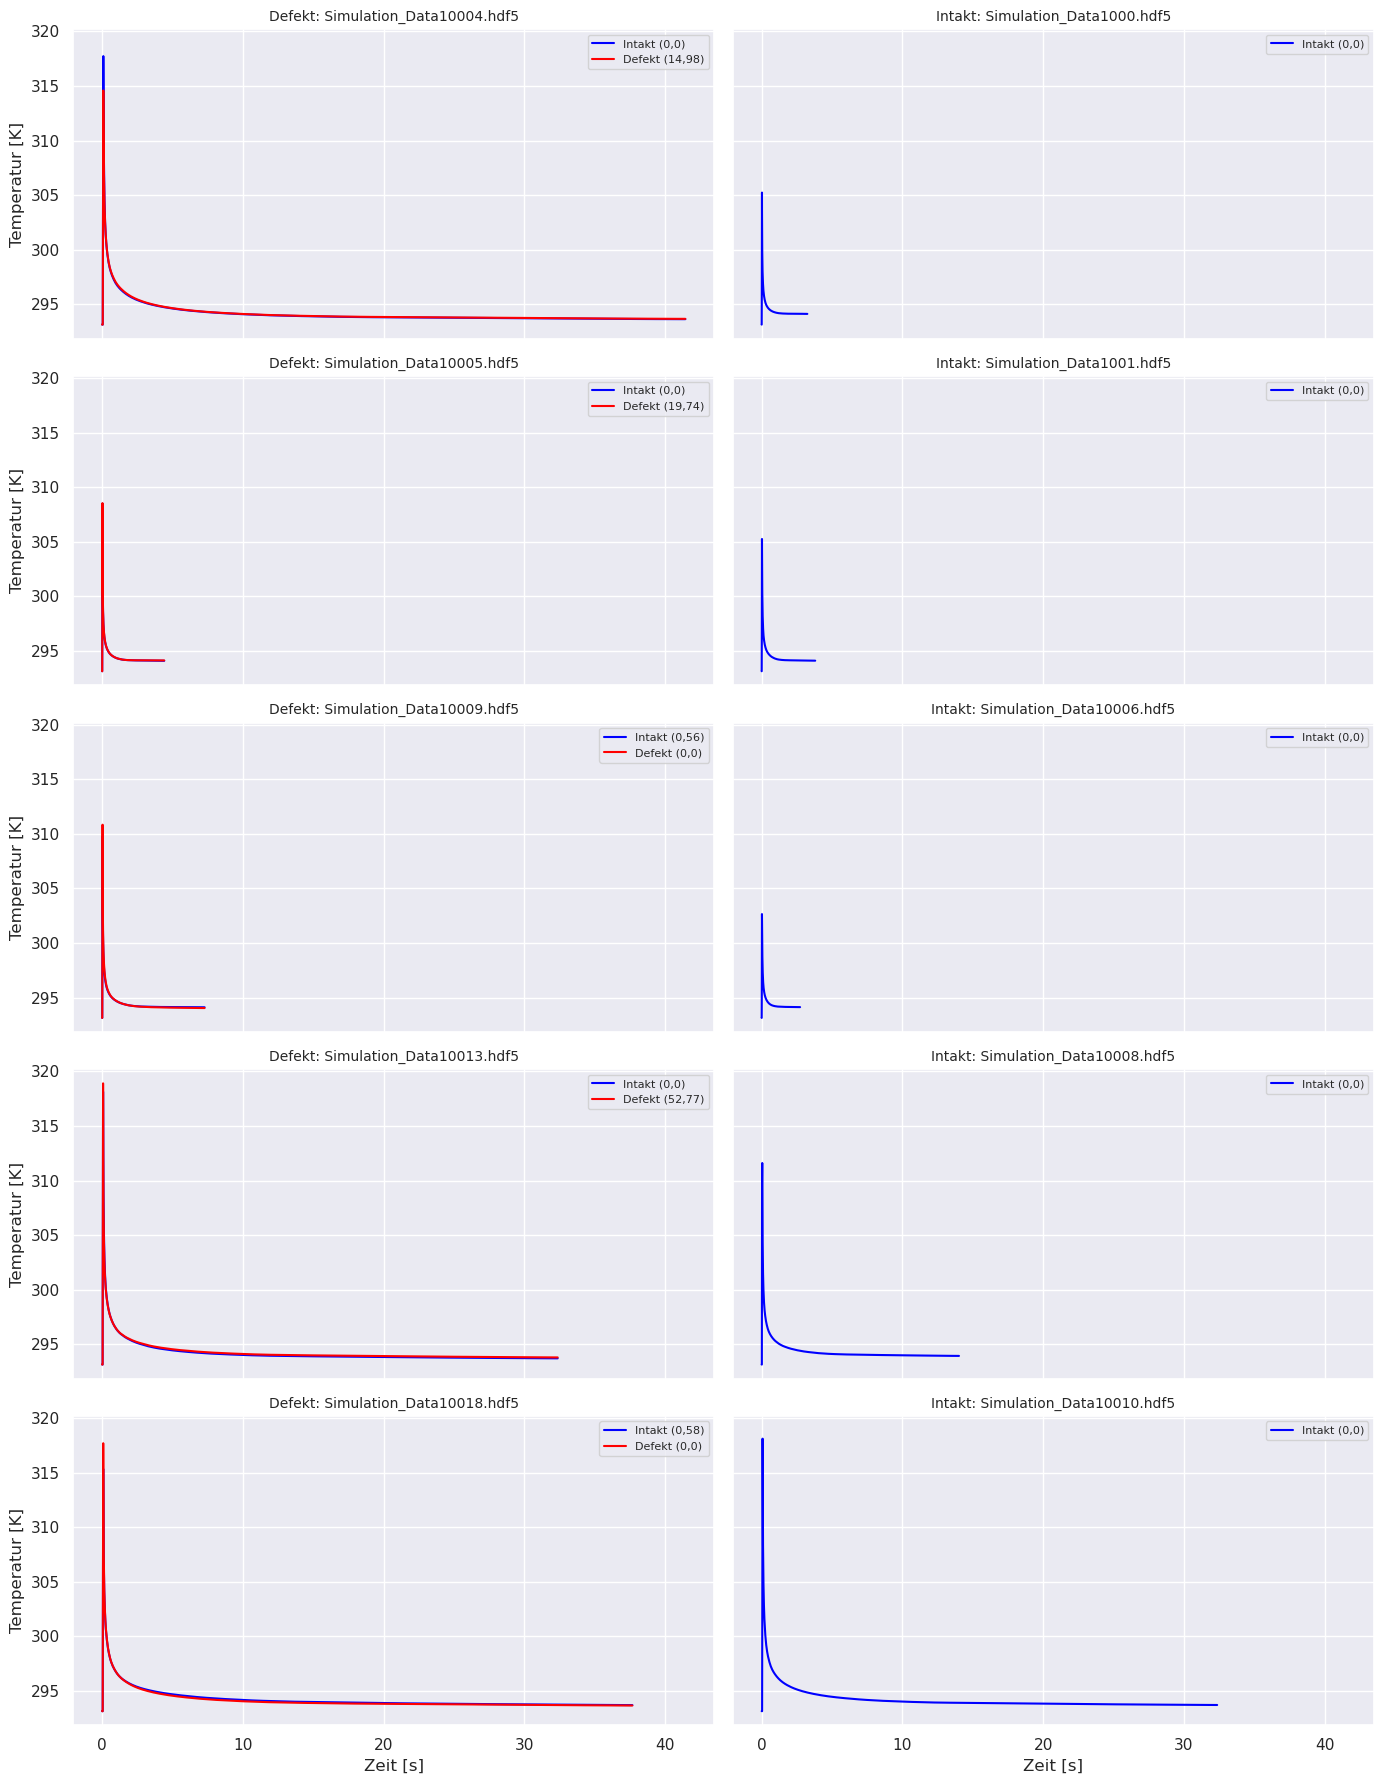

In [3]:
# 5x2 Raster erstellen, Achsen synchronisieren
fig, axes = plt.subplots(5, 2, figsize=(14, 18), sharex=True, sharey=True)

# Linke Spalte: Defekte
for i, file_name in enumerate(defect_files):
    full_path = base_path / "defect" / file_name
    plot_hdf5_to_ax(full_path, axes[i, 0], f"Defekt: {file_name}")

# Rechte Spalte: Keine Defekte
for i, file_name in enumerate(no_defect_files):
    full_path = base_path / "no-defect" / file_name
    plot_hdf5_to_ax(full_path, axes[i, 1], f"Intakt: {file_name}")

# Achsenbeschriftungen setzen
for ax in axes[-1, :]:
    ax.set_xlabel("Zeit [s]")
for ax in axes[:, 0]:
    ax.set_ylabel("Temperatur [K]")

plt.tight_layout()
plt.show()

Die Analyse der Temperaturkurven zeigt vier zentrale Herausforderungen für das Machine-Learning-Modell:

Visuelle Ähnlichkeit: Defekte und intakte Kurven überlappen makroskopisch fast vollständig – ein einfaches Schwellenwertverfahren reicht nicht; das Modell muss feinste dynamische Unterschiede (z. B. Abkühlverhalten) extrahieren.

Unterschiedliche Sequenzlängen: Die Aufzeichnungsdauern variieren stark (ca. 5–40 Sekunden). Für Modelle mit fester Eingabegröße (LSTM, 1D-CNN) müssen die Zeitreihen durch Padding oder Truncation harmonisiert werden.

Variierende Maximaltemperaturen: Die Temperaturpeaks schwanken (ca. 305–320 K). Ohne Normalisierung könnte das Modell fälschlich auf absolute Werte statt auf die Kurvenform achten; eine Skalierung pro Zeitreihe (Min-Max oder Z-Standardisierung) ist daher nötig.

Feature-Engineering: Da die Rohdaten schwer trennbar sind, kann die Berechnung der Abkühlrate (erste Ableitung) oder eine logarithmische Skalierung die relevanten Unterschiede deutlicher sichtbar machen und die Klassifikation erleichtern.